In [4]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
import operator

In [5]:
load_dotenv()

True

In [6]:
model = ChatGoogleGenerativeAI(model='gemini-4-hydrogen')

In [7]:
class EvalSchema(BaseModel):
    feedback: str = Field(description='Detailed feedback for the essay')
    score: int = Field(description='Score out of 10', ge=0, le=10)

In [8]:
structured_model = model.with_structured_output(EvalSchema)

In [9]:
essay = '''
India is rapidly emerging as a global powerhouse in Artificial Intelligence (AI), driven by a massive pool of tech talent, a booming startup ecosystem, and targeted government initiatives. Once primarily known as the world’s back-office for IT outsourcing, the nation is transitioning into a hub for deep-tech innovation and applied AI solutions. From transforming healthcare and agriculture to powering digital public infrastructure, AI is reshaping India’s economic and social landscape.
A major catalyst behind this surge is strong institutional support, anchored by the government's IndiaAI Mission. Launched with a substantial budget allocation, the mission focuses on building sovereign compute infrastructure, democratizing access to high-end GPUs, and fostering indigenous foundational models. Combined with initiatives like Bhashini—which uses AI to break language barriers across India's 22 official languages—the state is laying the groundwork for inclusive, population-scale AI adoption.
India’s vast and diverse data ecosystem gives it a unique advantage in developing practical AI applications. Leveraging its world-renowned Digital Public Infrastructure (DPI), such as Aadhaar and UPI, innovators are integrating AI into everyday services. In healthcare, AI-powered diagnostic tools are helping bridge the gap in rural areas by screening for diseases like tuberculosis and diabetic retinopathy. In agriculture, predictive analytics and computer vision assist millions of farmers with weather forecasting, crop monitoring, and pest control. Meanwhile, India’s enterprise and startup sectors—centered in hubs like Bengaluru, Hyderabad, and Pune—are building cutting-edge generative AI tools for global markets.
Despite this rapid momentum, India’s AI journey faces critical challenges. The nation must address a shortage of specialized research talent, close gaps in domestic semiconductor and compute hardware manufacturing, and ensure ethical governance. Issues such as algorithmic bias, data privacy under the Digital Personal Data Protection (DPDP) Act, and the potential displacement of entry-level IT and customer service jobs require careful policy navigation and massive workforce upskilling.
Ultimately, the rise of AI in India represents both an economic opportunity and a social revolution. By focusing on affordable, multilingual, and high-impact solutions tailored for developing economies, India is not merely adopting global AI trends—it is defining a distinct model of "AI for All." As infrastructure matures and talent continues to scale, India is well-positioned to lead the next wave of global technological transformation.
'''

In [10]:
prompt = f'Evaluate the language quality of the follwing essay and provide a feedback and assign a score out of 10 \n {essay}'
structured_model.invoke(prompt)

EvalSchema(feedback="The essay demonstrates exceptional language quality, characterized by strong clarity, coherence, and a polished, formal tone appropriate for an analytical overview. The structure flows logically across five well-organized paragraphs, using effective transitional phrases such as 'A major catalyst behind this surge,' 'Despite this rapid momentum,' and 'Ultimately' to guide the reader seamlessly from India's current trajectory to its challenges and future outlook. Vocabulary is sophisticated and precise, incorporating strong domain-specific terminology like 'sovereign compute infrastructure,' 'indigenous foundational models,' and 'algorithmic bias' without sacrificing readability. Grammar, syntax, and punctuation—including the effective use of em-dashes for parenthetical emphasis—are virtually flawless. The only minor area for stylistic improvement is the repetitive use of introductory participial and prepositional phrases to open sentences (e.g., 'Once primarily know

In [11]:
class UPSCState(TypedDict):
    essay: str
    language_fb: str
    analysis_fb: str
    clarity_fb: str
    overall_fb: str
    indiv_scores: Annotated[list[int], operator.add]
    avg_score: float

In [12]:
def eval_language(state: UPSCState):
    prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)
    return {'language_fb': output.feedback, 'indiv_scores': [output.score]}

def eval_analysis(state: UPSCState):
    prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)
    return {'analysis_fb': output.feedback, 'indiv_scores': [output.score]}

def eval_clarity(state: UPSCState):
    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)
    return {'clarity_fb': output.feedback, 'indiv_scores': [output.score]}

def final_eval(state: UPSCState):
    prompt = f'''Based on the following feedbacks create a summarized feedback \n 
    Language feedback - {state['language_fb']} \n 
    Depth of analysis feedback - {state['analysis_fb']} \n
    Clarity of thought feedback - {state['clarity_fb']}
    '''
    overall_fb = model.invoke(prompt)
    avg_score = sum(state['indiv_scores']) / len(state['indiv_scores'])
    return {'overall_fb': overall_fb, 'avg_score': [avg_score]}



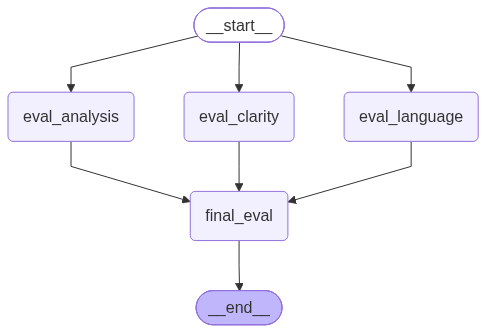

In [18]:
graph = StateGraph(UPSCState)

graph.add_node('eval_language', eval_language)
graph.add_node('eval_analysis', eval_analysis)
graph.add_node('eval_clarity', eval_clarity)
graph.add_node('final_eval', final_eval)

graph.add_edge(START, 'eval_language')
graph.add_edge(START, 'eval_analysis')
graph.add_edge(START, 'eval_clarity')

graph.add_edge('eval_language', 'final_eval')
graph.add_edge('eval_analysis', 'final_eval')
graph.add_edge('eval_clarity', 'final_eval')

graph.add_edge('final_eval', END)

workflow = graph.compile()
workflow

In [19]:
initial_state = {'essay': essay}
final_state = workflow.invoke(initial_state)
final_state

{'essay': '\nIndia is rapidly emerging as a global powerhouse in Artificial Intelligence (AI), driven by a massive pool of tech talent, a booming startup ecosystem, and targeted government initiatives. Once primarily known as the world’s back-office for IT outsourcing, the nation is transitioning into a hub for deep-tech innovation and applied AI solutions. From transforming healthcare and agriculture to powering digital public infrastructure, AI is reshaping India’s economic and social landscape.\nA major catalyst behind this surge is strong institutional support, anchored by the government\'s IndiaAI Mission. Launched with a substantial budget allocation, the mission focuses on building sovereign compute infrastructure, democratizing access to high-end GPUs, and fostering indigenous foundational models. Combined with initiatives like Bhashini—which uses AI to break language barriers across India\'s 22 official languages—the state is laying the groundwork for inclusive, population-sca